In [2]:
import numpy as np 
import math 
import pandas as pd
import json

## Importing of Dataset

In [3]:
X_train = pd.read_csv("smote/training_set.csv", header=None).values
Y_train = pd.read_csv("smote/training_labels.csv", header=None).values.astype(int).squeeze()
X_val = pd.read_csv("smote/validation_set.csv", header=None).values
Y_val = pd.read_csv("smote/validation_labels.csv", header=None).values.astype(int).squeeze()
test_inputs = np.loadtxt("test_set.csv", delimiter=",")


In [4]:
print("Training Set shape:", X_train.shape)
print("Validation Set shape:", X_val.shape)
print("Training Set Label shape:", Y_train.shape)
print("Validation Set Label shape:", Y_val.shape)

Training Set shape: (12200, 354)
Validation Set shape: (800, 354)
Training Set Label shape: (12200,)
Validation Set Label shape: (800,)


In [5]:
print("After SMOTE:", np.bincount(Y_val))

After SMOTE: [  0  99  99 105  95  92  98  94 118]


## One Hot Encoding
We need to make the classes instead of 1-8, it will have an 8 column of 1 or 0. Shift the index to 0-7 since the labels are 1-8.

In [6]:
Y_train = Y_train - 1
Y_val = Y_val - 1

In [7]:
n_classes = 8
Y_train = np.eye(n_classes)[Y_train]
Y_val = np.eye(n_classes)[Y_val]

In [8]:
print("Y_train shape:", Y_train.shape)
print("Y_val shape:", Y_val.shape)
print("Example one-hot vector:", Y_train[0])


Y_train shape: (12200, 8)
Y_val shape: (800, 8)
Example one-hot vector: [0. 1. 0. 0. 0. 0. 0. 0.]


## Applying SMOTE
In order to have a balanced dataset and to avoid overfitting, we must balance the dataset by increasing the data of the undersampled class.

In [9]:
class Activations:
    @staticmethod
    def logistic(z, a=2.0):
        return 1.0 / (1.0 + np.exp(-a*z))

    @staticmethod
    def d_logistic(y, a=2.0):
        return a * y * (1.0 - y)
    
    @staticmethod
    def tanh_scaled(z, a=1.716, b=2.0/3.0):
        return a * np.tanh(b * z)

    @staticmethod
    def d_tanh_scaled(y, a=1.716, b=2.0/3.0):
        return (b / a) * (a - y) * (a + y)

    @staticmethod
    def leaky_relu(z, neg_slope=0.01):
        return np.where(z > 0, z, neg_slope * z)

    @staticmethod
    def d_leaky_relu_from_z(z, neg_slope=0.01):
        return np.where(z > 0, 1.0, neg_slope)


In [10]:
class NeuralNetwork: 
    def __init__(
        self,
        input_size,
        hidden1_size,
        hidden2_size,
        output_size,
        act_hidden1=('tanh', {'a':1.716, 'b':2.0/3.0}),
        act_hidden2=('tanh', {'a':1.716, 'b':2.0/3.0}),
        act_output=('logistic', {'a':2.0}),
        batch_size=8,
        learning_rate=0.01,
        momentum=0.9,
        seed=42
    ):
        rng = np.random.default_rng(seed)
        self.in_dim = input_size
        self.h1 = hidden1_size
        self.h2 = hidden2_size
        self.out_dim = output_size
        self.batch_size = batch_size
        self.lr = learning_rate
        self.mu = momentum

        # Weights & biases
        self.W1 = rng.normal(0, 0.01, size=(self.in_dim, self.h1))
        self.b1 = np.zeros((1, self.h1))
        self.W2 = rng.normal(0, 0.01, size=(self.h1, self.h2))
        self.b2 = np.zeros((1, self.h2))
        self.W3 = rng.normal(0, 0.01, size=(self.h2, self.out_dim))
        self.b3 = np.zeros((1, self.out_dim))

        # Momentum buffers
        self.vW1 = np.zeros_like(self.W1)
        self.vb1 = np.zeros_like(self.b1)
        self.vW2 = np.zeros_like(self.W2)
        self.vb2 = np.zeros_like(self.b2)
        self.vW3 = np.zeros_like(self.W3)
        self.vb3 = np.zeros_like(self.b3)

        # Activation config
        self.act_h1_name, self.act_h1_params = act_hidden1
        self.act_h2_name, self.act_h2_params = act_hidden2
        self.act_out_name, self.act_out_params = act_output
        
    def forward_prop(self, X):
        self.Z1 = X @ self.W1 + self.b1
        self.A1 = self._act_forward(self.Z1, self.act_h1_name, self.act_h1_params)

        self.Z2 = self.A1 @ self.W2 + self.b2
        self.A2 = self._act_forward(self.Z2, self.act_h2_name, self.act_h2_params)

        self.Z3 = self.A2 @ self.W3 + self.b3
        self.A3 = self._act_forward(self.Z3, self.act_out_name, self.act_out_params)
        return self.A3
    
    def _act_forward(self, Z, act_name, act_params):
        if act_name == "tanh":
            return Activations.tanh_scaled(Z, **act_params)
        elif act_name == "sigmoid" or act_name == "logistic":
            return Activations.logistic(Z, **act_params)
        elif act_name == "leaky_relu":
            return Activations.leaky_relu(Z, **act_params)
        else:
            raise ValueError(f"Unknown activation function: {act_name}")    
    
    def backward_prop(self, X, Y):
        m = Y.shape[0]
        dA3 = self.A3 - Y # output error
        dZ3 = self._act_backward(dA3, self.Z3, self.act_out_name, self.act_out_params) # delta for output layer
        dW3 = (self.A2.T @ dZ3) / m # gradient for W3
        db3 = np.sum(dZ3, axis=0, keepdims=True) / m # gradient for b3

        # Update (with momentum)
        self.vW3 = self.mu * self.vW3 - self.lr * dW3
        self.vb3 = self.mu * self.vb3 - self.lr * db3

        self.W3 += self.vW3
        self.b3 += self.vb3
        
        dA2 = dZ3 @ self.W3.T
        dZ2 = self._act_backward(dA2, self.Z2, self.act_h2_name, self.act_h2_params)
        dW2 = (self.A1.T @ dZ2) / m
        db2 = np.sum(dZ2, axis=0, keepdims=True) / m
        
        # Update (with momentum)
        self.vW2 = self.mu * self.vW2 - self.lr * dW2
        self.vb2 = self.mu * self.vb2 - self.lr * db2
        self.W2 += self.vW2
        self.b2 += self.vb2
        
        dA1 = dZ2 @ self.W2.T
        dZ1 = self._act_backward(dA1, self.Z1, self.act_h1_name, self.act_h1_params)
        dW1 = (X.T @ dZ1) / m
        db1 = np.sum(dZ1, axis=0, keepdims=True) / m
        
        # Update (with momentum)
        self.vW1 = self.mu * self.vW1 - self.lr * dW1
        self.vb1 = self.mu * self.vb1 - self.lr * db1
        self.W1 += self.vW1
        self.b1 += self.vb1 
        
        return np.mean(0.5 * np.square(self.A3 - Y))
             
    def _act_backward(self, dA, Z, act_name, act_params):
        if act_name == "tanh":
            A = Activations.tanh_scaled(Z, **act_params)
            return dA * Activations.d_tanh_scaled(A, **act_params)
        elif act_name == "sigmoid" or act_name == "logistic":
            A = Activations.logistic(Z, **act_params)
            return dA * Activations.d_logistic(A, **act_params)
        elif act_name == "leaky_relu":
            return dA * Activations.d_leaky_relu_from_z(Z, **act_params)
        else:
            raise ValueError(f"Unknown activation function: {act_name}")
        
    

## Create Functions for saving training weights

In [11]:
def _flatten_parameters(model):
    return {
        "in_dim": int(model.in_dim),
        "h1": int(model.h1),
        "h2": int(model.h2),
        "out_dim": int(model.out_dim),
        "W1": model.W1.tolist(),
        "b1": model.b1.tolist(),
        "W2": model.W2.tolist(),
        "b2": model.b2.tolist(),
        "W3": model.W3.tolist(),
        "b3": model.b3.tolist()
    }

def save_networks_to_csv(network_map, filepath="results/trained_weights.csv"):
    records = []
    for name, model in network_map.items():
        params = _flatten_parameters(model)
        for param_name, value in params.items():
            records.append({
                "network": name,
                "parameter": param_name,
                "value": json.dumps(value)
            })
    pd.DataFrame(records).to_csv(filepath, index=False)

def load_network_from_csv(filepath, network_name):
    df = pd.read_csv(filepath)
    subset = df[df["network"] == network_name]
    if subset.empty:
        raise ValueError(f"No weights found for network {network_name} in {filepath}")
    params = {}
    for _, row in subset.iterrows():
        params[row["parameter"]] = json.loads(row["value"])
    return params


## Training Neural Network A 

With tanh for both hidden layer and logistic as the output layer activation

In [12]:
nn_a = NeuralNetwork(
    input_size=354,
    hidden1_size=256,
    hidden2_size=128,
    output_size=8,
    act_hidden1=('tanh', {'a':1.716, 'b':2.0/3.0}),
    act_hidden2=('tanh', {'a':1.716, 'b':2.0/3.0}),
    act_output=('logistic', {'a':2.0}),
    batch_size=8,
    learning_rate=0.01,
    momentum=0.9
)


In [13]:
epochs = 100
train_errors, val_errors, val_misclass = [], [], []

for epoch in range(epochs):
    # Shuffle training data
    perm = np.random.permutation(X_train.shape[0])
    X_train, Y_train = X_train[perm], Y_train[perm]

    # Mini-batch processing
    total_loss = 0
    for i in range(0, X_train.shape[0], nn_a.batch_size):
        Xb = X_train[i:i+nn_a.batch_size]
        Yb = Y_train[i:i+nn_a.batch_size]

        # Forward and backward pass
        nn_a.forward_prop(Xb)
        loss = nn_a.backward_prop(Xb, Yb)
        total_loss += loss * len(Xb)

    total_loss /= X_train.shape[0]
    train_errors.append(total_loss)

    # Every 5 epochs → validate
    if epoch % 5 == 0 or epoch == epochs - 1:
        nn_a.forward_prop(X_val)
        val_loss = np.mean(0.5 * np.square(nn_a.A3 - Y_val))
        preds = np.argmax(nn_a.A3, axis=1)
        actual = np.argmax(Y_val, axis=1)
        misclass = np.sum(preds != actual)
        val_errors.append(val_loss)
        val_misclass.append(misclass)
        print(f"Epoch {epoch:3d} | Train SSE={total_loss:.4f} | Val SSE={val_loss:.4f} | Misclass={misclass}")

# Save errors to file
pd.DataFrame({"train_sse": train_errors}).to_csv("results/training_errors_tanh.csv", index=False)
pd.DataFrame({"val_sse": val_errors, "misclass": val_misclass}).to_csv("results/validation_errors_tanh.csv", index=False)


Epoch   0 | Train SSE=0.0559 | Val SSE=0.0547 | Misclass=701
Epoch   5 | Train SSE=0.0236 | Val SSE=0.0217 | Misclass=163
Epoch  10 | Train SSE=0.0113 | Val SSE=0.0078 | Misclass=42
Epoch  15 | Train SSE=0.0071 | Val SSE=0.0048 | Misclass=32
Epoch  20 | Train SSE=0.0052 | Val SSE=0.0034 | Misclass=19
Epoch  25 | Train SSE=0.0040 | Val SSE=0.0037 | Misclass=23
Epoch  30 | Train SSE=0.0036 | Val SSE=0.0021 | Misclass=13
Epoch  35 | Train SSE=0.0029 | Val SSE=0.0023 | Misclass=17
Epoch  40 | Train SSE=0.0027 | Val SSE=0.0026 | Misclass=17
Epoch  45 | Train SSE=0.0023 | Val SSE=0.0021 | Misclass=13
Epoch  50 | Train SSE=0.0020 | Val SSE=0.0014 | Misclass=10
Epoch  55 | Train SSE=0.0019 | Val SSE=0.0012 | Misclass=8
Epoch  60 | Train SSE=0.0021 | Val SSE=0.0014 | Misclass=8
Epoch  65 | Train SSE=0.0018 | Val SSE=0.0011 | Misclass=6
Epoch  70 | Train SSE=0.0017 | Val SSE=0.0023 | Misclass=15
Epoch  75 | Train SSE=0.0015 | Val SSE=0.0012 | Misclass=7
Epoch  80 | Train SSE=0.0015 | Val SSE=0.0

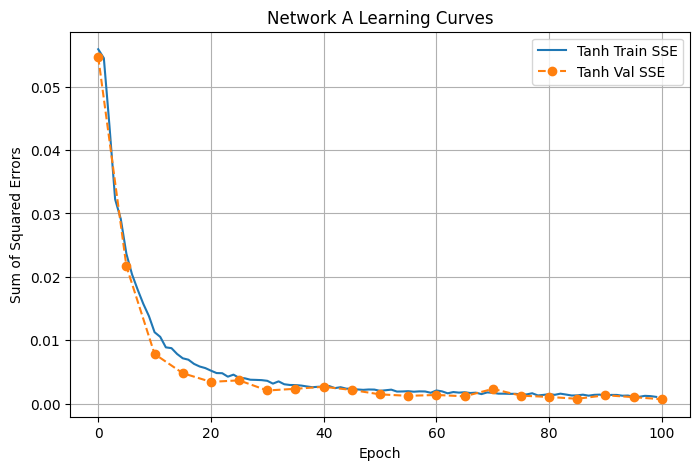

In [ ]:
import matplotlib.pyplot as plt

train_tanh = pd.read_csv("results/training_errors_tanh.csv")
val_tanh = pd.read_csv("results/validation_errors_tanh.csv")

val_epochs_tanh = [i*5 for i in range(len(val_tanh))]

plt.figure(figsize=(8,5))
plt.plot(range(len(train_tanh)), train_tanh["train_sse"], label="Tanh Train SSE", color="tab:blue")
plt.plot(val_epochs_tanh, val_tanh["val_sse"], "o--", label="Tanh Val SSE", color="tab:orange")
plt.title("Network A Learning Curves")
plt.xlabel("Epoch")
plt.ylabel("Sum of Squared Errors")
plt.legend()
plt.grid(True)
plt.show()


## Parameter finetuning 

Using different hidden layer size and parameter input, and finding the best config.

In [16]:
import time

configs = [
    (128, 64, 0.01, 0.9),
    (256, 128, 0.01, 0.9),
    (512, 256, 0.01, 0.9),
    (128, 64, 0.005, 0.9),
    (256, 128, 0.005, 0.9),
    (512, 256, 0.005, 0.9),
    (128, 64, 0.01, 0.9),
    (256, 128, 0.01, 0.9),
    (512, 256, 0.01, 0.9),
    (128, 64, 0.005, 0.95),
    (256, 128, 0.005, 0.95),
    (512, 256, 0.005, 0.95),
    (128, 64, 0.01, 0.95),
    (256, 128, 0.01, 0.95),
    (512, 256, 0.01, 0.95),
]

best_val = float('inf')
best_cfg = None
best_nn = None

for h1, h2, lr, mu in configs:
    print(f"\nTraining config: h1={h1}, h2={h2}, lr={lr}, mu={mu}")
    
    nn = NeuralNetwork(
        input_size=354, hidden1_size=h1, hidden2_size=h2, output_size=8,
        act_hidden1=('tanh', {'a':1.716, 'b':2.0/3.0}),
        act_hidden2=('tanh', {'a':1.716, 'b':2.0/3.0}),
        act_output=('logistic', {'a':2.0}),
        learning_rate=lr, momentum=mu, batch_size=8
    )

    epochs = 100
    train_errors, val_errors = [], []

    # 🕒 start timer
    start_time = time.time()

    for epoch in range(epochs):
        # training pass
        perm = np.random.permutation(X_train.shape[0])
        X_train, Y_train = X_train[perm], Y_train[perm]
        total_loss = 0
        for i in range(0, X_train.shape[0], nn.batch_size):
            Xb, Yb = X_train[i:i+nn.batch_size], Y_train[i:i+nn.batch_size]
            nn.forward_prop(Xb)
            total_loss += nn.backward_prop(Xb, Yb) * len(Xb)
        train_errors.append(total_loss / X_train.shape[0])

        # validation check
        if epoch % 5 == 0 or epoch == epochs - 1:
            nn.forward_prop(X_val)
            val_loss = np.mean(0.5 * np.square(nn.A3 - Y_val))
            val_errors.append(val_loss)

    # 🕒 stop timer
    end_time = time.time()
    elapsed = end_time - start_time

    # Print and compare
    final_val = val_errors[-1]
    print(f"  val_SSE={final_val:.4f} | time={elapsed:.2f} sec ({elapsed/60:.2f} min)")

    if final_val < best_val:
        best_val = final_val
        best_cfg = (h1, h2, lr, mu)
        best_nn = nn

print(f"\n✅ Best config: {best_cfg} | val_SSE={best_val:.4f}")



Training config: h1=128, h2=64, lr=0.01, mu=0.9
  val_SSE=0.0021 | time=361.96 sec (6.03 min)

Training config: h1=256, h2=128, lr=0.01, mu=0.9
  val_SSE=0.0006 | time=519.39 sec (8.66 min)

Training config: h1=512, h2=256, lr=0.01, mu=0.9
  val_SSE=0.0012 | time=1298.07 sec (21.63 min)

Training config: h1=128, h2=64, lr=0.005, mu=0.9
  val_SSE=0.0014 | time=277.99 sec (4.63 min)

Training config: h1=256, h2=128, lr=0.005, mu=0.9
  val_SSE=0.0015 | time=817.81 sec (13.63 min)

Training config: h1=512, h2=256, lr=0.005, mu=0.9
  val_SSE=0.0014 | time=2193.63 sec (36.56 min)

Training config: h1=128, h2=64, lr=0.01, mu=0.9
  val_SSE=0.0007 | time=191.98 sec (3.20 min)

Training config: h1=256, h2=128, lr=0.01, mu=0.9
  val_SSE=0.0010 | time=474.04 sec (7.90 min)

Training config: h1=512, h2=256, lr=0.01, mu=0.9
  val_SSE=0.0015 | time=1987.98 sec (33.13 min)

Training config: h1=128, h2=64, lr=0.005, mu=0.95
  val_SSE=0.0015 | time=341.43 sec (5.69 min)

Training config: h1=256, h2=128

## Save the best weights for Network A

In [17]:
np.savez("results/trained_weights_tanh.npz",
         W1=best_nn.W1, b1=best_nn.b1,
         W2=best_nn.W2, b2=best_nn.b2,
         W3=best_nn.W3, b3=best_nn.b3)

save_networks_to_csv({"tanh": best_nn}, "results/trained_weights.csv")


## Train Network B (Leaky ReLU)

In [18]:
h1, h2, lr, mu = best_cfg

nn_b = NeuralNetwork(
    input_size=354, hidden1_size=h1, hidden2_size=h2, output_size=8,
    act_hidden1=('leaky_relu', {'neg_slope':0.01}),
    act_hidden2=('leaky_relu', {'neg_slope':0.01}),
    act_output=('logistic', {'a':2.0}),
    learning_rate=lr, momentum=mu, batch_size=8
)

In [19]:
epochs = 100
train_errors_b, val_errors_b, val_misclass_b = [], [], []

for epoch in range(epochs):
    # Shuffle training data
    perm = np.random.permutation(X_train.shape[0])
    X_train, Y_train = X_train[perm], Y_train[perm]

    # Mini-batch processing
    total_loss = 0
    for i in range(0, X_train.shape[0], nn_b.batch_size):
        Xb = X_train[i:i+nn_b.batch_size]
        Yb = Y_train[i:i+nn_b.batch_size]

        # Forward and backward pass
        nn_b.forward_prop(Xb)
        loss = nn_b.backward_prop(Xb, Yb)
        total_loss += loss * len(Xb)

    total_loss /= X_train.shape[0]
    train_errors_b.append(total_loss)

    # Every 5 epochs → validate
    if epoch % 5 == 0 or epoch == epochs - 1:
        nn_b.forward_prop(X_val)
        val_loss = np.mean(0.5 * np.square(nn_b.A3 - Y_val))
        preds = np.argmax(nn_b.A3, axis=1)
        actual = np.argmax(Y_val, axis=1)
        misclass = np.sum(preds != actual)
        val_errors_b.append(val_loss)
        val_misclass_b.append(misclass)
        print(f"Epoch {epoch:3d} | Train SSE={total_loss:.4f} | Val SSE={val_loss:.4f} | Misclass={misclass}")

# Save errors to file
pd.DataFrame({"train_sse": train_errors_b}).to_csv("results/training_errors_leakyrelu.csv", index=False)
pd.DataFrame({"val_sse": val_errors_b, "misclass": val_misclass_b}).to_csv("results/validation_errors_leakyrelu.csv", index=False)


Epoch   0 | Train SSE=0.0556 | Val SSE=0.0546 | Misclass=630
Epoch   5 | Train SSE=0.0112 | Val SSE=0.0094 | Misclass=69
Epoch  10 | Train SSE=0.0054 | Val SSE=0.0032 | Misclass=24
Epoch  15 | Train SSE=0.0033 | Val SSE=0.0033 | Misclass=30
Epoch  20 | Train SSE=0.0027 | Val SSE=0.0021 | Misclass=14
Epoch  25 | Train SSE=0.0023 | Val SSE=0.0091 | Misclass=75
Epoch  30 | Train SSE=0.0017 | Val SSE=0.0009 | Misclass=6
Epoch  35 | Train SSE=0.0015 | Val SSE=0.0013 | Misclass=11
Epoch  40 | Train SSE=0.0019 | Val SSE=0.0009 | Misclass=7
Epoch  45 | Train SSE=0.0012 | Val SSE=0.0017 | Misclass=16
Epoch  50 | Train SSE=0.0010 | Val SSE=0.0005 | Misclass=3
Epoch  55 | Train SSE=0.0012 | Val SSE=0.0041 | Misclass=33
Epoch  60 | Train SSE=0.0012 | Val SSE=0.0004 | Misclass=3
Epoch  65 | Train SSE=0.0009 | Val SSE=0.0005 | Misclass=3
Epoch  70 | Train SSE=0.0008 | Val SSE=0.0005 | Misclass=4
Epoch  75 | Train SSE=0.0009 | Val SSE=0.0009 | Misclass=9
Epoch  80 | Train SSE=0.0008 | Val SSE=0.0004 

In [20]:
np.savez("results/trained_weights_leakyrelu.npz",
         W1=nn_b.W1, b1=nn_b.b1,
         W2=nn_b.W2, b2=nn_b.b2,
         W3=nn_b.W3, b3=nn_b.b3)

save_networks_to_csv({"tanh": best_nn, "leakyrelu": nn_b}, "results/trained_weights.csv")


## Plotting the errors for each neural network A and B

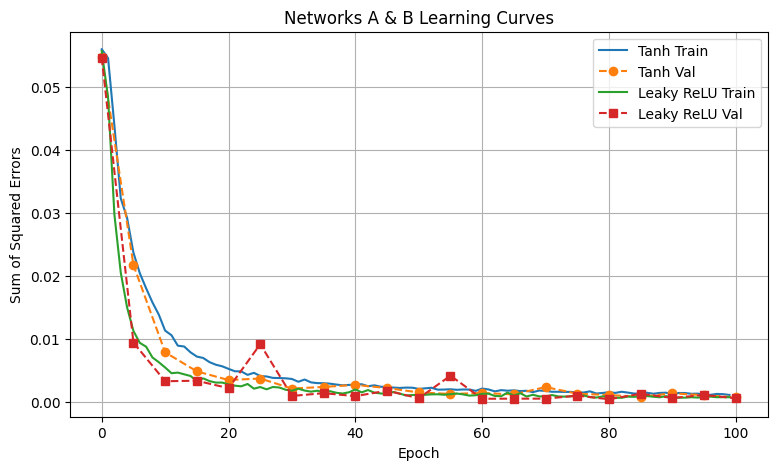

In [21]:
import matplotlib.pyplot as plt

train_tanh = pd.read_csv("results/training_errors_tanh.csv")
val_tanh = pd.read_csv("results/validation_errors_tanh.csv")
train_leaky = pd.read_csv("results/training_errors_leakyrelu.csv")
val_leaky = pd.read_csv("results/validation_errors_leakyrelu.csv")

val_epochs_tanh = [i*5 for i in range(len(val_tanh))]
val_epochs_leaky = [i*5 for i in range(len(val_leaky))]

plt.figure(figsize=(9,5))
plt.plot(range(len(train_tanh)), train_tanh["train_sse"], label="Tanh Train", color="tab:blue")
plt.plot(val_epochs_tanh, val_tanh["val_sse"], "o--", label="Tanh Val", color="tab:orange")
plt.plot(range(len(train_leaky)), train_leaky["train_sse"], label="Leaky ReLU Train", color="tab:green")
plt.plot(val_epochs_leaky, val_leaky["val_sse"], "s--", label="Leaky ReLU Val", color="tab:red")
plt.title("Networks A & B Learning Curves")
plt.xlabel("Epoch")
plt.ylabel("Sum of Squared Errors")
plt.legend()
plt.grid(True)
plt.show()


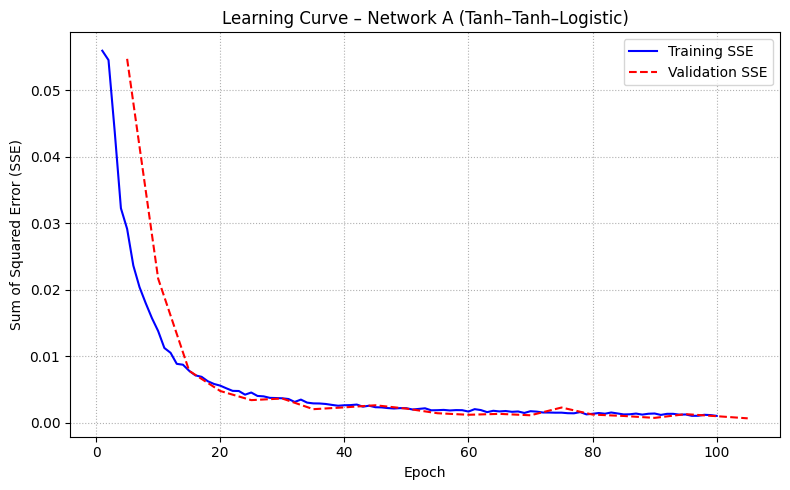

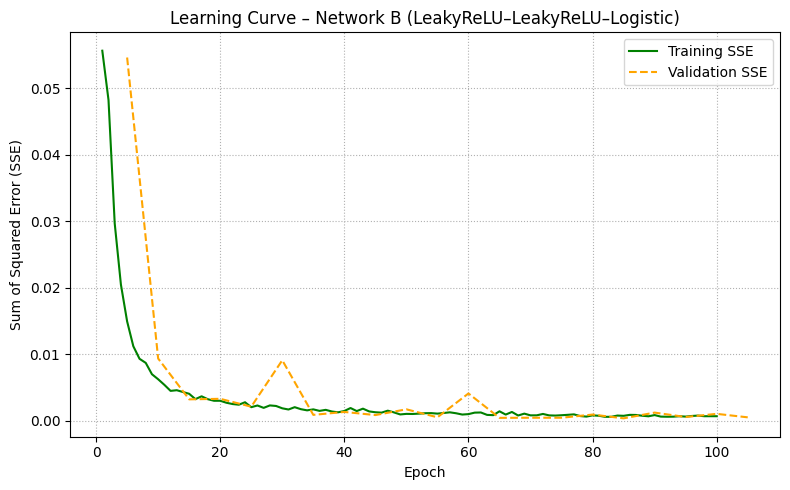

In [27]:
# --- Load training and validation CSVs ---
train_tanh = pd.read_csv("results/training_errors_tanh.csv")
val_tanh = pd.read_csv("results/validation_errors_tanh.csv")
train_leaky = pd.read_csv("results/training_errors_leakyrelu.csv")
val_leaky = pd.read_csv("results/validation_errors_leakyrelu.csv")

# === Create epoch ranges ===
epochs_train_tanh = np.arange(1, len(train_tanh) + 1)
epochs_val_tanh = np.arange(5, 5 * len(val_tanh) + 1, 5)

epochs_train_relu = np.arange(1, len(train_leaky) + 1)
epochs_val_relu = np.arange(5, 5 * len(val_leaky) + 1, 5)

# === Plot for Tanh Network (Network A) ===
plt.figure(figsize=(8, 5))
plt.plot(epochs_train_tanh, train_tanh["train_sse"], label="Training SSE", color="blue")
plt.plot(epochs_val_tanh, val_tanh["val_sse"], label="Validation SSE", color="red", linestyle="--")
plt.title("Learning Curve – Network A (Tanh–Tanh–Logistic)")
plt.xlabel("Epoch")
plt.ylabel("Sum of Squared Error (SSE)")
plt.legend()
plt.grid(True, linestyle=":")
plt.tight_layout()
plt.savefig("results/learning_curve_tanh.png", dpi=300, bbox_inches="tight")
plt.show()

# === Plot for Leaky ReLU Network (Network B) ===
plt.figure(figsize=(8, 5))
plt.plot(epochs_train_relu, train_leaky["train_sse"], label="Training SSE", color="green")
plt.plot(epochs_val_relu, val_leaky["val_sse"], label="Validation SSE", color="orange", linestyle="--")
plt.title("Learning Curve – Network B (LeakyReLU–LeakyReLU–Logistic)")
plt.xlabel("Epoch")
plt.ylabel("Sum of Squared Error (SSE)")
plt.legend()
plt.grid(True, linestyle=":")
plt.tight_layout()
plt.savefig("results/learning_curve_leakyrelu.png", dpi=300, bbox_inches="tight")
plt.show()

## Predict on Test Set

In [22]:
# Load model A weights from CSV and predict on data.csv
tanh_params = load_network_from_csv("results/trained_weights.csv", "tanh")
nn_a_pred = NeuralNetwork(
    input_size=int(tanh_params["in_dim"]),
    hidden1_size=int(tanh_params["h1"]),
    hidden2_size=int(tanh_params["h2"]),
    output_size=int(tanh_params["out_dim"]),
    act_hidden1=("tanh", {"a": 1.716, "b": 2.0/3.0}),
    act_hidden2=("tanh", {"a": 1.716, "b": 2.0/3.0}),
    act_output=("logistic", {"a": 2.0}),
    batch_size=8,
    learning_rate=0.0,
    momentum=0.0
)
nn_a_pred.W1 = np.array(tanh_params["W1"]).reshape(nn_a_pred.W1.shape)
nn_a_pred.b1 = np.array(tanh_params["b1"]).reshape(nn_a_pred.b1.shape)
nn_a_pred.W2 = np.array(tanh_params["W2"]).reshape(nn_a_pred.W2.shape)
nn_a_pred.b2 = np.array(tanh_params["b2"]).reshape(nn_a_pred.b2.shape)
nn_a_pred.W3 = np.array(tanh_params["W3"]).reshape(nn_a_pred.W3.shape)
nn_a_pred.b3 = np.array(tanh_params["b3"]).reshape(nn_a_pred.b3.shape)

nn_a_pred.forward_prop(test_inputs)
test_preds_A = np.argmax(nn_a_pred.A3, axis=1) + 1
np.savetxt("results/predictions_for_test_tanh.csv", test_preds_A, fmt="%d", delimiter=",")


In [23]:
# Load model B weights from CSV and predict on data.csv
leaky_params = load_network_from_csv("results/trained_weights.csv", "leakyrelu")
nn_b_pred = NeuralNetwork(
    input_size=int(leaky_params["in_dim"]),
    hidden1_size=int(leaky_params["h1"]),
    hidden2_size=int(leaky_params["h2"]),
    output_size=int(leaky_params["out_dim"]),
    act_hidden1=("leaky_relu", {"neg_slope": 0.01}),
    act_hidden2=("leaky_relu", {"neg_slope": 0.01}),
    act_output=("logistic", {"a": 2.0}),
    batch_size=8,
    learning_rate=0.0,
    momentum=0.0
)
nn_b_pred.W1 = np.array(leaky_params["W1"]).reshape(nn_b_pred.W1.shape)
nn_b_pred.b1 = np.array(leaky_params["b1"]).reshape(nn_b_pred.b1.shape)
nn_b_pred.W2 = np.array(leaky_params["W2"]).reshape(nn_b_pred.W2.shape)
nn_b_pred.b2 = np.array(leaky_params["b2"]).reshape(nn_b_pred.b2.shape)
nn_b_pred.W3 = np.array(leaky_params["W3"]).reshape(nn_b_pred.W3.shape)
nn_b_pred.b3 = np.array(leaky_params["b3"]).reshape(nn_b_pred.b3.shape)

nn_b_pred.forward_prop(test_inputs)
test_preds_B = np.argmax(nn_b_pred.A3, axis=1) + 1
np.savetxt("results/predictions_for_test_leakyrelu.csv", test_preds_B, fmt="%d", delimiter=",")


## Validation Metrics for Networks A and B


In [24]:
# Evaluate trained networks on validation set
val_labels = np.argmax(Y_val, axis=1)

metrics_rows = []
class_names = [str(i) for i in range(1, 9)]
num_classes = len(class_names)

def _confusion_matrix(y_true, y_pred, k):
    cm = np.zeros((k, k), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    return cm

def _per_class_metrics(cm):
    precisions, recalls, f1s, supports = [], [], [], []
    for idx in range(cm.shape[0]):
        tp = cm[idx, idx]
        fp = cm[:, idx].sum() - tp
        fn = cm[idx, :].sum() - tp
        support = cm[idx, :].sum()
        precision = tp / (tp + fp) if (tp + fp) else 0.0
        recall = tp / (tp + fn) if (tp + fn) else 0.0
        f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) else 0.0
        precisions.append(precision)
        recalls.append(recall)
        f1s.append(f1)
        supports.append(support)
    return np.array(precisions), np.array(recalls), np.array(f1s), np.array(supports)

def _matthews_corrcoef(cm):
    t_sum = float(cm.sum())
    col_sum = cm.sum(axis=0).astype(float)
    row_sum = cm.sum(axis=1).astype(float)
    diag_sum = float(cm.trace())
    numerator = (diag_sum * t_sum) - np.sum(row_sum * col_sum)
    term1 = t_sum ** 2 - np.sum(col_sum ** 2)
    term2 = t_sum ** 2 - np.sum(row_sum ** 2)
    denominator_term = term1 * term2
    if denominator_term <= 0.0:
        return 0.0
    denominator = math.sqrt(denominator_term)
    return numerator / denominator if denominator else 0.0

for name, model, act_label in [("tanh", nn_a, "Network A (tanh)"), ("leakyrelu", nn_b, "Network B (Leaky ReLU)")]:
    probs = model.forward_prop(X_val)
    preds = np.argmax(probs, axis=1)

    conf = _confusion_matrix(val_labels, preds, num_classes)
    per_class_precision, per_class_recall, per_class_f1, per_class_support = _per_class_metrics(conf)
    accuracy = conf.trace() / conf.sum() if conf.sum() else 0.0
    precision_macro = per_class_precision.mean()
    recall_macro = per_class_recall.mean()
    f1_macro = per_class_f1.mean()
    mcc = _matthews_corrcoef(conf)

    metrics_rows.append({
        "network": act_label,
        "accuracy": accuracy,
        "precision_macro": precision_macro,
        "recall_macro": recall_macro,
        "f1_macro": f1_macro,
        "matthews_corrcoef": mcc
    })

    print(f"Validation classification report - {act_label}:")
    header = f"{'Class':>6} {'Precision':>10} {'Recall':>10} {'F1-Score':>10} {'Support':>10}"
    print(header)
    print('-' * len(header))
    for idx, cls in enumerate(class_names):
        print(f"{cls:>6} {per_class_precision[idx]:10.4f} {per_class_recall[idx]:10.4f} {per_class_f1[idx]:10.4f} {per_class_support[idx]:10d}")
    print(f"{'macro':>6} {precision_macro:10.4f} {recall_macro:10.4f} {f1_macro:10.4f} {per_class_support.sum():10d}")

    conf_df = pd.DataFrame(conf, index=class_names, columns=class_names)
    conf_df.index.name = "actual"
    conf_df.columns.name = "predicted"
    conf_df.to_csv(f"results/confusion_matrix_{name}.csv")




Validation classification report - Network A (tanh):
 Class  Precision     Recall   F1-Score    Support
--------------------------------------------------
     1     0.9898     0.9798     0.9848         99
     2     0.9900     1.0000     0.9950         99
     3     1.0000     1.0000     1.0000        105
     4     0.9896     1.0000     0.9948         95
     5     0.9892     1.0000     0.9946         92
     6     1.0000     1.0000     1.0000         98
     7     1.0000     1.0000     1.0000         94
     8     1.0000     0.9831     0.9915        118
 macro     0.9948     0.9954     0.9951        800
Validation classification report - Network B (Leaky ReLU):
 Class  Precision     Recall   F1-Score    Support
--------------------------------------------------
     1     1.0000     0.9697     0.9846         99
     2     0.9900     1.0000     0.9950         99
     3     1.0000     1.0000     1.0000        105
     4     0.9896     1.0000     0.9948         95
     5     0.9892    

In [25]:
metrics_df = pd.DataFrame(metrics_rows)
metrics_df.to_csv("results/validation_metrics.csv", index=False)
metrics_df

,network,accuracy,precision_macro,recall_macro,f1_macro,matthews_corrcoef
0,Network A (tanh),0.995,0.994828,0.995356,0.995070,0.994288
1,Network B (Leaky ReLU),0.995,0.994788,0.995153,0.994925,0.994294
